In [1]:
import sys
sys.path.append('/home/users/zwb3/research/falling-models/')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.model_selection import train_test_split
from data.MGH.processing.calc_sofa import calc_sofa

from falling_trees import falling_rashomon_cpp as gravitree
from falling_trees.frl_rashomon_set_alg_falling_constraint_v2 import print_tree
from falling_trees.binarize_dataset import binarize_dataset, cut

# MGH Data Case Study
### This file written by @Zack-Boner

## Description of data

The dataset used in this case study was provided by the Massachussetts General Hospital, by a team led by Dr. Brandon Westover.
The data consists of 12 features typically used to compute the Sequential Organ Failure Assessment (SOFA) score, which is used to determine the level of acuity and mortality risk for patients admitted to the intensive care unit.
An online calculator for the SOFA score may be found at the following link: [https://www.mdcalc.com/calc/691/sequential-organ-failure-assessment-sofa-score#next-steps].

The label describes whether the patient died during their stay in the ICU.

In [2]:
SOFA_FEATURES = [
    'Total_Bilirubin_mg_per_dL', 'MAP', 'Creatinine_mg_per_dL', 'Dobutamine_any_dose', 'Dopamine_μg_kg_min',
    'Epinephrine_μg_kg_min', 'GCS', 'mech_vent_cpap', 'Norepinephrine_μg_kg_min', 'PaO2_FiO2', 'Platelets_10_3_per_ml',
    'Urine_output_mL'
]
label = 'died_in_ICU'

In [3]:
df = pd.read_csv('data/MGH/processed_data/full_patient_df.csv')
X = df[SOFA_FEATURES]
y = df[label]
sofa_scores = X.fillna(0).apply(calc_sofa, axis=1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=11)

In [4]:
len(y)-sum(y)

4351

In [5]:
print(len(y_train), y_train.mean())

4000 0.12875


In [6]:
balance_factor = 2
X_train_pos = X_train.loc[y_train==1]
X_train_neg = X_train.loc[y_train==0]
X_train_balanced = pd.concat([X_train_pos, X_train_neg.sample(n=X_train_pos.shape[0] * balance_factor, random_state=11)])
y_train_balanced = pd.Series([1] * (X_train_pos.shape[0]) + [0] * (X_train_pos.shape[0] * balance_factor))

In [7]:
print(len(y_train_balanced), y_train_balanced.mean())

1545 0.3333333333333333


In [8]:
len(y_train_balanced)-sum(y_train_balanced)

1030

In [9]:
df_to_binarize = X_train_balanced.fillna(-1).copy()
df_to_binarize[label] = y_train.astype(int)
df_final, thresholds, header, threshold_guess_time = binarize_dataset(df_to_binarize, 50)
X_train_final, y_train_final = df_final.iloc[:, :-1], df_final.iloc[:, -1]
X_test_final = cut(X_test, thresholds)[header]
y_test_final = y_test
X_train_final.head(5)

,Total_Bilirubin_mg_per_dL<=0.15000000223517418,Total_Bilirubin_mg_per_dL<=0.3500000089406967,Total_Bilirubin_mg_per_dL<=0.45000000298023224,Total_Bilirubin_mg_per_dL<=1.550000011920929,Total_Bilirubin_mg_per_dL<=1.8499999642372131,Total_Bilirubin_mg_per_dL<=2.350000023841858,Total_Bilirubin_mg_per_dL<=5.3500001430511475,Total_Bilirubin_mg_per_dL<=6.3500001430511475,MAP<=57.83333396911621,Creatinine_mg_per_dL<=1.1749999523162842,...,GCS<=1.0,mech_vent_cpap<=0.5,Norepinephrine_μg_kg_min<=14.25,Norepinephrine_μg_kg_min<=19.899999618530273,Norepinephrine_μg_kg_min<=64.69999885559082,Platelets_10_3_per_ml<=42.5,Platelets_10_3_per_ml<=48.5,Platelets_10_3_per_ml<=221.5,Platelets_10_3_per_ml<=323.0,Platelets_10_3_per_ml<=428.0
0,0,0,0,1,1,1,1,1,0,1,...,1,1,1,1,1,0,0,0,1,1
1,0,1,1,1,1,1,1,1,1,1,...,0,0,0,0,1,0,0,1,1,1
2,0,0,0,1,1,1,1,1,1,0,...,0,1,1,1,1,0,0,1,1,1
3,0,0,0,1,1,1,1,1,0,1,...,0,0,1,1,1,0,0,1,1,1
4,1,1,1,1,1,1,1,1,1,1,...,1,0,1,1,1,0,0,0,1,1


In [25]:
eps=0.02
depth=5
branching_cost=0.01
min_support=0.02
dump_path='/home/users/zwb3/research/falling-models/data/MGH/case_study/rsets/falling-tree-bc01.jsonl'
# dump_path='/dev/null'

result = gravitree.run_from_xy(
        X_train_final.values,
        y_train_final.values,
        branching_cost=branching_cost,
        min_support=min_support,
        depth=depth,
        eps=eps,
        enable_falling_constraint=True,
        dump_rset_jsonl=dump_path,
        use_heap=True,
        use_current_leaf_prob=True,
        rule_list_mode=False,
        budget_override=None,
        max_cache_size=10**7,
        lam=0.0,
    )
print(result['best_tree_str'])

Node(feature=15)
  Node(feature=4)
    Leaf(pred_prob=0.766, objective=0.010)
    Node(feature=8)
      Node(feature=25)
        Leaf(pred_prob=0.619, objective=0.010)
        Node(feature=2)
          Leaf(pred_prob=0.574, objective=0.017)
          Leaf(pred_prob=0.317, objective=0.013)
      Leaf(pred_prob=0.641, objective=0.021)
  Node(feature=22)
    Leaf(pred_prob=0.707, objective=0.008)
    Node(feature=6)
      Leaf(pred_prob=0.706, objective=0.006)
      Node(feature=4)
        Leaf(pred_prob=0.419, objective=0.017)
        Leaf(pred_prob=0.227, objective=0.160)



In [26]:
result

{'best_loss': 0.2721359223300971,
 'pmax': 0.765625,
 'rset_size': 529,
 'best_tree_str': 'Node(feature=15)\n  Node(feature=4)\n    Leaf(pred_prob=0.766, objective=0.010)\n    Node(feature=8)\n      Node(feature=25)\n        Leaf(pred_prob=0.619, objective=0.010)\n        Node(feature=2)\n          Leaf(pred_prob=0.574, objective=0.017)\n          Leaf(pred_prob=0.317, objective=0.013)\n      Leaf(pred_prob=0.641, objective=0.021)\n  Node(feature=22)\n    Leaf(pred_prob=0.707, objective=0.008)\n    Node(feature=6)\n      Leaf(pred_prob=0.706, objective=0.006)\n      Node(feature=4)\n        Leaf(pred_prob=0.419, objective=0.017)\n        Leaf(pred_prob=0.227, objective=0.160)\n',
 'cache_size': 2191406,
 'cache_hits': 6757767,
 'cache_misses': 6944046,
 'non_falling_new': 0}

In [27]:
import json

models = []
preds = []
aucs = []
for i in range(result['rset_size']):
    tree_dict = json.loads(open(dump_path).readlines()[i])
    pred = gravitree.predict(tree_dict['tree'], X_test_final.values, 0.5)
    auc = roc_auc_score(y_test_final, pred)
    models.append(tree_dict)
    aucs.append(auc)
    preds.append(pred)
    print(f"Model {i}: AUC = {auc}")
    
print(len(np.unique(preds, axis=0)))

Model 0: AUC = 0.631010651132329
Model 1: AUC = 0.631010651132329
Model 2: AUC = 0.631010651132329
Model 3: AUC = 0.631010651132329
Model 4: AUC = 0.631010651132329
Model 5: AUC = 0.631010651132329
Model 6: AUC = 0.631010651132329
Model 7: AUC = 0.6208334769570163
Model 8: AUC = 0.6208334769570163
Model 9: AUC = 0.631010651132329
Model 10: AUC = 0.631010651132329
Model 11: AUC = 0.631010651132329
Model 12: AUC = 0.631010651132329
Model 13: AUC = 0.631010651132329
Model 14: AUC = 0.631010651132329
Model 15: AUC = 0.631010651132329
Model 16: AUC = 0.631010651132329
Model 17: AUC = 0.6208334769570163
Model 18: AUC = 0.6208334769570163
Model 19: AUC = 0.631010651132329
Model 20: AUC = 0.631010651132329
Model 21: AUC = 0.6241253317707076
Model 22: AUC = 0.6241253317707076
Model 23: AUC = 0.6241253317707076
Model 24: AUC = 0.6139481575953949
Model 25: AUC = 0.6241253317707076
Model 26: AUC = 0.6241253317707076
Model 27: AUC = 0.6241253317707076
Model 28: AUC = 0.6241253317707076
Model 29: AU

In [28]:
df

,Admission,SexDSC,PatientRaceDSC,EthnicGroupDSC,Age,Hours_to_mortality,Days_to_mortality,Months_to_mortality,Years_to_mortality,Time_to_death,...,Epinephrine_μg_kg_min,GCS,mech_vent_cpap,Norepinephrine_μg_kg_min,PaO2,FiO2,PaO2_FiO2,Platelets_10_3_per_ml,Urine_output_mL,died_in_ICU
0,0,Male,White,Not Hispanic,79,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,1.0,0.0,71.0,0.4,142.0,503.0,NaN,False
1,1,Male,White,Not Hispanic,63,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,1.0,10.5,125.0,0.4,208.0,155.0,1080.0,False
2,2,Female,White,Not Hispanic,75,8.0,0.0,9.0,3.0,1370 days 08:14:00,...,0.0,NaN,0.0,0.0,90.0,0.3,300.0,252.0,NaN,False
3,3,Female,White,Not Hispanic,78,8.0,20.0,0.0,0.0,20 days 08:53:00,...,0.0,12.0,0.0,0.0,NaN,NaN,NaN,207.0,1466.0,True
4,4,Male,White,Not Hispanic,21,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,0.0,37.5,NaN,NaN,NaN,358.0,1185.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,4995,Female,White,Not Hispanic,89,NaN,NaN,NaN,NaN,NaN,...,0.0,15.0,0.0,0.0,NaN,NaN,NaN,127.0,270.0,False
4996,4996,Female,Asian,Not Hispanic,89,18.0,5.0,1.0,0.0,36 days 18:22:00,...,0.0,15.0,0.0,0.0,NaN,NaN,NaN,114.0,755.0,False
4997,4997,Female,Asian,Not Hispanic,89,21.0,1.0,0.0,0.0,1 days 21:13:00,...,0.0,5.0,1.0,37.5,NaN,NaN,NaN,197.0,365.0,True
4998,4998,Male,White,Not Hispanic,72,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,0.0,0.0,NaN,NaN,NaN,159.0,975.0,False


In [29]:
sexes = df.loc[X_test_final.index, 'SexDSC']
races = df.loc[X_test_final.index, 'PatientRaceDSC']

In [30]:
def demographic_parity_difference(y_true, y_pred, sensitive_attr):
    groups = sensitive_attr.unique()
    if 'Unknown' in groups:
        groups = groups[groups != 'Unknown']
    positive_rates = {}
    for group in groups:
        mask = (sensitive_attr == group)
        positive_rates[group] = y_pred[mask].mean()
    max_rate = max(positive_rates.values())
    min_rate = min(positive_rates.values())
    return max_rate - min_rate

dp_diffs_sex = []
for i, pred in enumerate(preds):
    dp_diff = demographic_parity_difference(y_test_final.values, pred, sexes)
    dp_diffs_sex.append(dp_diff)
    
dp_diffs_race = []
for i, pred in enumerate(preds):
    dp_diff = demographic_parity_difference(y_test_final.values, pred, races)
    dp_diffs_race.append(dp_diff)

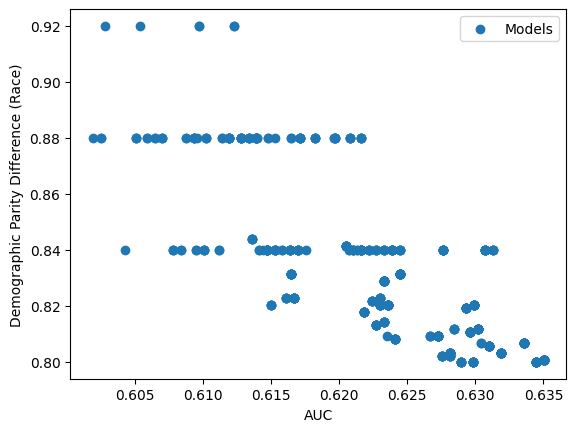

In [31]:
plt.scatter(aucs, dp_diffs_race, label='Models')
plt.xlabel('AUC')
plt.ylabel('Demographic Parity Difference (Race)')
plt.legend()
plt.show()

In [11]:
for i, feature in enumerate(X_train_final.columns):
    print(i, feature)

0 Total_Bilirubin_mg_per_dL<=0.15000000223517418
1 Total_Bilirubin_mg_per_dL<=0.3500000089406967
2 Total_Bilirubin_mg_per_dL<=0.45000000298023224
3 Total_Bilirubin_mg_per_dL<=1.550000011920929
4 Total_Bilirubin_mg_per_dL<=1.8499999642372131
5 Total_Bilirubin_mg_per_dL<=2.350000023841858
6 Total_Bilirubin_mg_per_dL<=5.3500001430511475
7 Total_Bilirubin_mg_per_dL<=6.3500001430511475
8 MAP<=57.83333396911621
9 Creatinine_mg_per_dL<=1.1749999523162842
10 Creatinine_mg_per_dL<=1.465000033378601
11 Creatinine_mg_per_dL<=1.4950000047683716
12 Creatinine_mg_per_dL<=1.5750000476837158
13 Creatinine_mg_per_dL<=1.5950000286102295
14 Creatinine_mg_per_dL<=1.774999976158142
15 Creatinine_mg_per_dL<=1.9350000023841858
16 Dobutamine_any_dose<=0.5
17 Epinephrine_μg_kg_min<=15.949999809265137
18 GCS<=1.0
19 mech_vent_cpap<=0.5
20 Norepinephrine_μg_kg_min<=14.25
21 Norepinephrine_μg_kg_min<=19.899999618530273
22 Norepinephrine_μg_kg_min<=64.69999885559082
23 Platelets_10_3_per_ml<=42.5
24 Platelets_10_3

In [21]:
eps=0.01
depth=4
branching_cost=1.0
min_support=0.05
# dump_path='/home/users/zwb3/research/falling-models/data/MGH/case_study/rsets'
dump_path='/dev/null'

rl_result = gravitree.run_from_xy(
        X_train_final.values,
        y_train_final.values,
        branching_cost=branching_cost,
        min_support=min_support,
        depth=depth,
        eps=eps,
        enable_falling_constraint=True,
        dump_rset_jsonl=dump_path,
        use_heap=True,
        use_current_leaf_prob=True,
        rule_list_mode=False,
        budget_override=None,
        max_cache_size=10**7,
        lam=0.0,
    )

In [22]:
rl_result

{'best_loss': 0.2822006472491909,
 'pmax': 0.7849462365591398,
 'rset_size': 6,
 'best_tree_str': 'Node(feature=22)\n  Leaf(pred_prob=0.785, objective=0.013)\n  Node(feature=5)\n    Leaf(pred_prob=0.608, objective=0.030)\n    Node(feature=26)\n      Leaf(pred_prob=0.393, objective=0.031)\n      Node(feature=18)\n        Leaf(pred_prob=0.300, objective=0.124)\n        Leaf(pred_prob=0.226, objective=0.083)\n',
 'cache_size': 81740,
 'cache_hits': 111832,
 'cache_misses': 219119,
 'non_falling_new': 0}

In [23]:
print(rl_result['best_tree_str'])

Node(feature=22)
  Leaf(pred_prob=0.785, objective=0.013)
  Node(feature=5)
    Leaf(pred_prob=0.608, objective=0.030)
    Node(feature=26)
      Leaf(pred_prob=0.393, objective=0.031)
      Node(feature=18)
        Leaf(pred_prob=0.300, objective=0.124)
        Leaf(pred_prob=0.226, objective=0.083)



In [41]:
for i, feature in enumerate(X_train_final.columns):
    print(i, feature)

0 Total_Bilirubin_mg_per_dL<=0.15000000223517418
1 Total_Bilirubin_mg_per_dL<=0.3500000089406967
2 Total_Bilirubin_mg_per_dL<=0.45000000298023224
3 Total_Bilirubin_mg_per_dL<=1.550000011920929
4 Total_Bilirubin_mg_per_dL<=1.8499999642372131
5 Total_Bilirubin_mg_per_dL<=2.350000023841858
6 Total_Bilirubin_mg_per_dL<=5.3500001430511475
7 Total_Bilirubin_mg_per_dL<=6.3500001430511475
8 MAP<=57.83333396911621
9 Creatinine_mg_per_dL<=1.1749999523162842
10 Creatinine_mg_per_dL<=1.465000033378601
11 Creatinine_mg_per_dL<=1.4950000047683716
12 Creatinine_mg_per_dL<=1.5750000476837158
13 Creatinine_mg_per_dL<=1.5950000286102295
14 Creatinine_mg_per_dL<=1.774999976158142
15 Creatinine_mg_per_dL<=1.9350000023841858
16 Dobutamine_any_dose<=0.5
17 Epinephrine_μg_kg_min<=15.949999809265137
18 GCS<=1.0
19 mech_vent_cpap<=0.5
20 Norepinephrine_μg_kg_min<=14.25
21 Norepinephrine_μg_kg_min<=19.899999618530273
22 Norepinephrine_μg_kg_min<=64.69999885559082
23 Platelets_10_3_per_ml<=42.5
24 Platelets_10_3

In [38]:
eps=0.01
depth=3
branching_cost=0
min_support=0.00
# dump_path='/home/users/zwb3/research/falling-models/data/MGH/case_study/rsets'
dump_path='/dev/null'

full_result = gravitree.run_from_xy(
        X_train_final.values,
        y_train_final.values,
        branching_cost=branching_cost,
        min_support=min_support,
        depth=depth,
        eps=eps,
        enable_falling_constraint=True,
        dump_rset_jsonl=dump_path,
        use_heap=True,
        use_current_leaf_prob=True,
        rule_list_mode=False,
        budget_override=None,
        max_cache_size=10**7,
        lam=0.0,
    )

In [39]:
full_result

{'best_loss': 0.2614886731391586,
 'pmax': 0.8695652173913043,
 'rset_size': 126,
 'best_tree_str': 'Node(feature=11)\n  Node(feature=21)\n    Node(feature=12)\n      Leaf(pred_prob=0.748, objective=0.019)\n      Leaf(pred_prob=0.200, objective=0.001)\n    Node(feature=3)\n      Leaf(pred_prob=0.725, objective=0.012)\n      Leaf(pred_prob=0.397, objective=0.074)\n  Node(feature=24)\n    Node(feature=22)\n      Leaf(pred_prob=0.625, objective=0.006)\n      Leaf(pred_prob=0.220, objective=0.140)\n    Node(feature=3)\n      Leaf(pred_prob=0.870, objective=0.002)\n      Leaf(pred_prob=0.308, objective=0.008)\n',
 'cache_size': 46093,
 'cache_hits': 51394,
 'cache_misses': 96085,
 'non_falling_new': 0}

In [40]:
print(full_result['best_tree_str'])

Node(feature=11)
  Node(feature=21)
    Node(feature=12)
      Leaf(pred_prob=0.748, objective=0.019)
      Leaf(pred_prob=0.200, objective=0.001)
    Node(feature=3)
      Leaf(pred_prob=0.725, objective=0.012)
      Leaf(pred_prob=0.397, objective=0.074)
  Node(feature=24)
    Node(feature=22)
      Leaf(pred_prob=0.625, objective=0.006)
      Leaf(pred_prob=0.220, objective=0.140)
    Node(feature=3)
      Leaf(pred_prob=0.870, objective=0.002)
      Leaf(pred_prob=0.308, objective=0.008)



In [18]:
from pystreed import STreeDClassifier

In [19]:
X_train_final_ = X_train_final.copy()
X_train_final_.columns = [f"{i}" for i, feature in enumerate(X_train_final.columns)]
streed = STreeDClassifier(optimization_task="cost-complex-accuracy", max_depth=5, cost_complexity=0.003)
streed.fit(X_train_final_, y_train_final)
streed.print_tree()

16 not satisfied
|   Label: 1
16 satisfied
|   9 not satisfied
|   |   18 not satisfied
|   |   |   5 not satisfied
|   |   |   |   2 not satisfied
|   |   |   |   |   Label: 1
|   |   |   |   2 satisfied
|   |   |   |   |   Label: 0
|   |   |   5 satisfied
|   |   |   |   23 not satisfied
|   |   |   |   |   Label: 0
|   |   |   |   23 satisfied
|   |   |   |   |   Label: 1
|   |   18 satisfied
|   |   |   Label: 1
|   9 satisfied
|   |   19 not satisfied
|   |   |   Label: 0
|   |   19 satisfied
|   |   |   Label: 1


In [51]:
eps=0.
depth=4
branching_cost=0.005
min_support=0.01
dump_path='/home/users/zwb3/research/falling-models/data/MGH/case_study/rsets/falling-tree-bc01.jsonl'
# dump_path='/dev/null'

result = gravitree.run_from_xy(
        X_train_final.values,
        y_train_final.values,
        branching_cost=branching_cost,
        min_support=min_support,
        depth=depth,
        eps=eps,
        enable_falling_constraint=True,
        dump_rset_jsonl=dump_path,
        use_heap=True,
        use_current_leaf_prob=True,
        rule_list_mode=False,
        budget_override=None,
        max_cache_size=10**7,
        lam=0.0,
    )
print(result['best_tree_str'])

Node(feature=3)
  Node(feature=22)
    Leaf(pred_prob=0.897, objective=0.002)
    Node(feature=24)
      Node(feature=10)
        Leaf(pred_prob=0.699, objective=0.014)
        Leaf(pred_prob=0.284, objective=0.014)
      Leaf(pred_prob=0.848, objective=0.003)
  Node(feature=15)
    Node(feature=21)
      Leaf(pred_prob=0.724, objective=0.010)
      Node(feature=25)
        Leaf(pred_prob=0.617, objective=0.012)
        Leaf(pred_prob=0.417, objective=0.038)
    Node(feature=22)
      Leaf(pred_prob=0.633, objective=0.007)
      Node(feature=8)
        Leaf(pred_prob=0.214, objective=0.127)
        Leaf(pred_prob=0.310, objective=0.029)



In [52]:
eps=0.
depth=4
branching_cost=0.01
min_support=0.01
dump_path='/home/users/zwb3/research/falling-models/data/MGH/case_study/rsets/falling-tree-bc01.jsonl'
# dump_path='/dev/null'

result = gravitree.run_from_xy(
        X_train_final.values,
        y_train_final.values,
        branching_cost=branching_cost,
        min_support=min_support,
        depth=depth,
        eps=eps,
        enable_falling_constraint=True,
        dump_rset_jsonl=dump_path,
        use_heap=True,
        use_current_leaf_prob=True,
        rule_list_mode=False,
        budget_override=None,
        max_cache_size=10**7,
        lam=0.0,
    )
print(result['best_tree_str'])

Node(feature=15)
  Node(feature=2)
    Leaf(pred_prob=0.668, objective=0.042)
    Node(feature=25)
      Leaf(pred_prob=0.625, objective=0.010)
      Node(feature=8)
        Leaf(pred_prob=0.317, objective=0.013)
        Leaf(pred_prob=0.565, objective=0.006)
  Node(feature=22)
    Leaf(pred_prob=0.707, objective=0.008)
    Node(feature=6)
      Leaf(pred_prob=0.706, objective=0.006)
      Node(feature=26)
        Leaf(pred_prob=0.369, objective=0.027)
        Leaf(pred_prob=0.224, objective=0.150)



In [ ]:
eps=0.
depth=4
branching_cost=0.02
min_support=0.01
dump_path='/home/users/zwb3/research/falling-models/data/MGH/case_study/rsets/falling-tree-bc01.jsonl'
# dump_path='/dev/null'

result = gravitree.run_from_xy(
        X_train_final.values,
        y_train_final.values,
        branching_cost=branching_cost,
        min_support=min_support,
        depth=depth,
        eps=eps,
        enable_falling_constraint=True,
        dump_rset_jsonl=dump_path,
        use_heap=True,
        use_current_leaf_prob=True,
        rule_list_mode=False,
        budget_override=None,
        max_cache_size=10**7,
        lam=0.0,
    )
print(result['best_tree_str'])

Node(feature=16)
  Leaf(pred_prob=0.842, objective=0.002)
  Node(feature=22)
    Leaf(pred_prob=0.775, objective=0.013)
    Node(feature=6)
      Leaf(pred_prob=0.714, objective=0.010)
      Node(feature=15)
        Leaf(pred_prob=0.508, objective=0.076)
        Leaf(pred_prob=0.235, objective=0.174)

